# 1 · Veri kaynağı ve veri yükleme (Kriter 2)

**Bu notebook ne gösteriyor:** Veri nereden geldi, ham dosyalar neye benziyor, nasıl okunuyor ve ham hâlden işlenmiş hâle
geçerken kaç kayıt kaldı.

- **Kaynak:** HPDmobile, Jacoby ve ark. 2021, *Scientific Data*. figshare koleksiyonu 5364449. Lisans **CC0** (serbest).
- **Boyut:** 58 dosya, 50,9 GB zip. İçinde ~41 milyon küçük kamera karesi var; açılsa 250 GB'ı geçer.
- **Bizim yöntem:** zip'ler klasöre açılmadan, içinden akış hâlinde okunur (`src/build.py --fetch`): indir → oku → işlenmiş
  hâlini `data/processed/` altına yaz → zip'i sil. Sunum için her evden 1 saatlik ham örnek `data/samples/` altında tutuldu.

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


## 1.1 Yazarların metadata'sı: evler

Veri setiyle birlikte gelen `Home_overview.csv`: kaç kişi yaşıyor, kaç kutu (hub) kurulmuş, kaç gün kayıt var, zamanın yüzde
kaçında ev dolu.

In [2]:
META = INTERIM / "meta" / "metadata"
home = pd.read_csv(META / "Home_overview.csv")
home.columns = ["Ev", "Yaşayan", "Evcil hayvan", "Tür", "Alan (m²)", "İzlenen alan (%)", "Hub", "Gün", "Dolu oranı"]
home

,Ev,Yaşayan,Evcil hayvan,Tür,Alan (m²),İzlenen alan (%),Hub,Gün,Dolu oranı
0,H1,4 adults,1 cat,House,149,32,5,30,0.82
1,H2,1 adult,NaN,Apartment,72,53,4,17,0.61
2,H3,4 adults,1 dog,House,285,28,5,35,0.78
3,H4,3 adults,NaN,Apartment,93,36,5,17,0.82
4,H5,2 adults,1 cat,Apartment,54,48,5,15,0.76
5,H6,1 adult,NaN,Apartment,62,58,4,38,0.47


**Gözlem:** H2 ve H6'da tek kişi yaşıyor, bu evlerde "2+" sınıfı olmayacak. Kutular yalnız ortak alanlara kurulmuş:
evin %28–58'i izleniyor. Yani yatak odasındaki biri sensöre görünmeyebilir; etiket ise evin tamamı için.

In [3]:
pd.read_csv(META / "Hardware_overview.csv")

,Equipment,Make / Model,Use
0,Single-board computer (SBC),Raspberry Pi 3,Data collection platform
1,Camera,Raspberry Pi Camera Module v2,Image collection
2,Microphone,Knowles SPH0645,Audio collection
3,Gas sensor,Sensirion SGP30,TVOC \ eCO$_2$ readings
4,Temperature and humidity sensor,Aosong DHT22,Temperature \ rH readings
5,Light sensor,Avago APDS-9301,Illuminance readings
6,% Distance sensor,ST VL53L1X,Distance to nearest object
7,Battery pack,Romoss Solo 5 Power Bank,Supply short-term power to sensor hubs
8,Wireless router,Cradlepoint COR IBR600B,On-site network connection
9,Server,Antsle one Pro 8-Cores,On-site data storage


Her kutuda (hub) bir **Raspberry Pi** bilgisayar, kamera, mikrofon ve ortam sensörleri var. Bu bilgi ileride önemli:
kutunun içindeki bilgisayar ısındığı için sıcaklık sensörü evi olduğundan sıcak gösteriyor (Notebook 6).

## 1.2 Ham dosyalar neye benziyor?

Her modalitenin ham hâlini tek tek açıyoruz. Dosyalar `data/samples/` (1 saatlik ham örnek) ve `data/interim/` (küçük dosyalar:
etiket, ortam, karanlık kare listesi) altında.

In [4]:
# Etiket (groundtruth): günde bir CSV, 10 saniyede bir satır
gt = pd.read_csv(INTERIM / "H1" / "2019-11-26_H1_groundtruth.csv")
print("satır:", len(gt), "| sütunlar:", list(gt.columns))
gt.iloc[1020:1026]

satır: 8640 | sütunlar: ['timestamp', 'occupied', 'number']


,timestamp,occupied,number
1020,2019-11-26 02:50:00,1,2
1021,2019-11-26 02:50:10,1,2
1022,2019-11-26 02:50:20,1,2
1023,2019-11-26 02:50:30,1,2
1024,2019-11-26 02:50:40,1,2
1025,2019-11-26 02:50:50,1,2


`occupied` = evde biri var mı (0/1), `number` = kaç kişi. Etiket **10 saniyelik ızgarada**: 00:00:00, 00:00:10, …
Günde 24 × 360 = 8.640 satır. Projedeki örnek birimi bu yüzden 10 saniye.

In [5]:
# Ortam sensörleri: hub başına günde bir CSV, yine 10 saniyede bir
env = pd.read_csv(INTERIM / "H1" / "H1_RS2_ENV" / "2019-11-26_RS2_H1_env.csv", index_col=0, parse_dates=True)
print("satır:", len(env)); env.loc["2019-11-26 17:00:00":"2019-11-26 17:00:40"]

satır: 8640


,tvoc_ppb,temp_c,rh_percent,light_lux,co2eq_ppm,co2eq_base,tvoc_base,hub,home
2019-11-26 17:00:00,0.0,25.299999,21.799999,28.0,400.0,35191.0,35727.0,RS2,H1
2019-11-26 17:00:10,0.0,25.299999,21.799999,28.0,400.0,35191.0,35728.0,RS2,H1
2019-11-26 17:00:20,0.0,25.299999,21.799999,28.0,400.0,35191.0,35728.0,RS2,H1
2019-11-26 17:00:30,0.0,25.299999,21.799999,28.0,400.0,35191.0,35729.0,RS2,H1
2019-11-26 17:00:40,0.0,25.299999,21.799999,28.0,400.0,35191.0,35729.0,RS2,H1


Beş sensör: TVOC (havadaki uçucu gazlar, ppb), sıcaklık (°C), bağıl nem (%), ışık (lux), eCO2 (karbondioksit, ppm).

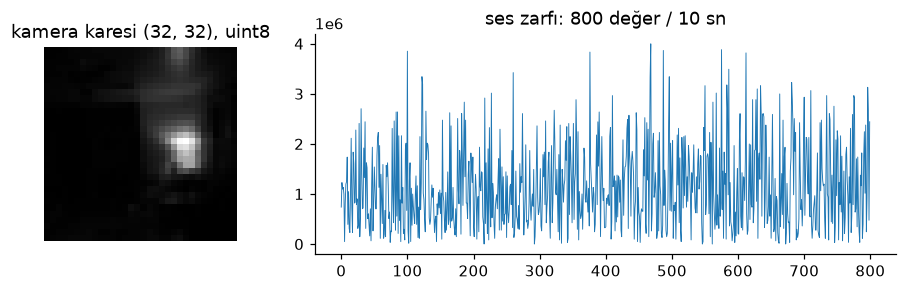

kare piksel aralığı: 0 – 171 | ses aralığı: 699 – 3,998,395


In [6]:
from PIL import Image
S = ROOT / "data" / "samples" / "H1"
png = S / "2019-11-26" / "1700" / "2019-11-26_170005_RS2_H1.png"
kare = np.asarray(Image.open(png).convert("L"))
ses = np.loadtxt(S / "H1_RS2_AUDIO" / "2019-11-26" / "1700" / "2019-11-26_170000_RS2_H1.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 2.6), gridspec_kw={"width_ratios": [1, 3]})
ax[0].imshow(kare, cmap="gray"); ax[0].set_title(f"kamera karesi {kare.shape}, {kare.dtype}"); ax[0].axis("off")
ax[1].plot(ses, lw=0.6); ax[1].set_title(f"ses zarfı: {len(ses)} değer / 10 sn")
plt.show()
print("kare piksel aralığı:", kare.min(), "–", kare.max(), "| ses aralığı:", f"{ses.min():,.0f} – {ses.max():,.0f}")

- **Görüntü:** 32×32 piksel, gri, saniyede 1 kare. Gizlilik için yazarlar bu kadar küçültmüş: yüz tanınmaz.
- **Ses:** gerçek ses kaydı değil; 10 saniyede 800 sayılık bir **ses şiddeti eğrisi** (zarf). Konuşma anlaşılmaz.
  Değerler çok geniş aralıkta (yüzlerden milyonlara), bu yüzden ileride logaritma alacağız (Notebook 5).

In [7]:
# Yazarların ek dosyaları: karanlık kare listesi ve "kamerada insan var mı" (zone) etiketi
dark = pd.read_csv(INTERIM / "H1" / "H1_RS1_DARKIMAGES" / "2019-11-26_RS1_H1_darkimages.csv", header=None, names=["zaman"])
zone = pd.read_csv(INTERIM / "H1" / "H1_RS1_ZONELABELS" / "2019-11-26_RS1_H1_zonelabels.csv")
print("karanlık diye silinen kare (bir gün, bir hub):", len(dark)); display(dark.head(3))
print("zone etiketi satırı:", len(zone)); display(zone.head(3))

karanlık diye silinen kare (bir gün, bir hub): 47606


,zaman
0,2019-11-26 00:00:03
1,2019-11-26 00:00:04
2,2019-11-26 00:00:05


zone etiketi satırı: 38852


,timestamp,occupied
0,2019-11-26 06:24:25,0
1,2019-11-26 06:24:26,0
2,2019-11-26 06:24:27,0


- **DARKIMAGES:** Işık kapalıyken çekilen kareler zip'e konmamış, yalnız zamanları listelenmiş. "Kare yok" ile "karanlık"
  ayrımını bu listeyle yapıyoruz.
- **ZONELABELS:** Yazarların kareler üzerinde çalıştırdığı insan algılayıcının çıktısı. Etiket kalitesini kontrol etmek
  için kullanıyoruz (Notebook 3).

## 1.3 Dosya adından zaman ve kutu bilgisi

Ham dosyaların içinde zaman yok; zaman **dosya adında**. `build.name_ts` bunu ayıklar. Eşleştirmenin ilk adımı bu.

In [8]:
from build import name_ts
for ad in ["2019-11-26_170005_RS2_H1.png", "2019-11-26_170000_RS2_H1.csv", "bozuk_ad.png"]:
    print(f"{ad:32s} →", name_ts(ad))

2019-11-26_170005_RS2_H1.png     → (Timestamp('2019-11-26 17:00:05'), 'RS2')
2019-11-26_170000_RS2_H1.csv     → (Timestamp('2019-11-26 17:00:00'), 'RS2')
bozuk_ad.png                     → None


## 1.4 İşlenmiş veri: ne oluştu?

Her ev için `data/processed/<ev>/` altında: etiket tablosu, her hub için görüntü/ses/ortam dizileri ve sayaçlar (`stats.json`).
Bütün diziler **aynı satır sayısına** sahip: satır *i* = o evin *i*. 10 saniyelik penceresi. Eşleştirme bu yüzden kolay.

In [9]:
rows = []
for f in sorted((OUT / "H1").iterdir()):
    if f.suffix == ".npy":
        a = np.load(f, mmap_mode="r"); rows.append((f.name, a.shape, str(a.dtype), f"{f.stat().st_size/1e6:,.0f} MB"))
    else:
        rows.append((f.name, "", "", f"{f.stat().st_size/1e6:,.1f} MB"))
pd.DataFrame(rows, columns=["dosya", "şekil", "tip", "boyut"])

,dosya,şekil,tip,boyut
0,RS1_aud.npy,"(257845, 800)",float16,413 MB
1,RS1_aud.parquet,,,0.0 MB
2,RS1_env.npy,"(257845, 5)",float32,5 MB
3,RS1_img.npy,"(257845, 32, 32)",uint8,264 MB
4,RS1_img.parquet,,,0.0 MB
5,RS2_aud.npy,"(257845, 800)",float16,413 MB
6,RS2_aud.parquet,,,0.0 MB
7,RS2_env.npy,"(257845, 5)",float32,5 MB
8,RS2_img.npy,"(257845, 32, 32)",uint8,264 MB
9,RS2_img.parquet,,,0.1 MB


`(257845, 32, 32)` = H1'in 257.845 penceresi için birer 32×32 kare. Ses `float16` (yarım hassasiyet) saklanıyor: disk
yetmediği için; logaritma sonrası değerler küçük olduğundan hassasiyet kaybı önemsiz.

## 1.5 Veri kaybı dökümü: ham → nihai (yönergenin istediği tablo)

`stats.json` her adımda kaç kayıt okunduğunu, kaçının eşleştiğini, kaçının düştüğünü kaydediyor. Rapordaki sayılar buradan.

In [10]:
T = []
for h in HOMES:
    st = json.loads((OUT / h / "stats.json").read_text())
    img = [v for k, v in st.items() if k.endswith("/img")]; aud = [v for k, v in st.items() if k.endswith("/aud")]
    T.append({"Ev": h, "Pencere (etiket)": st["labels"]["rows"], "Hub": len(img),
              "Kare dosyası": sum(v["files"] for v in img), "Kare ızgara dışı (düştü)": sum(v["outside_grid"] for v in img),
              "Bozuk kare": sum(v["bad_shape"] for v in img),
              "Ses dosyası": sum(v["files"] for v in aud), "Ses eşleşti": sum(v["matched"] for v in aud),
              "Ses ızgara dışı": sum(v["outside_grid"] for v in aud), "Bozuk ses": sum(v["bad"] for v in aud)})
T = pd.DataFrame(T).set_index("Ev"); T.loc["Toplam"] = T.sum()
T

,Pencere (etiket),Hub,Kare dosyası,Kare ızgara dışı (düştü),Bozuk kare,Ses dosyası,Ses eşleşti,Ses ızgara dışı,Bozuk ses
Ev,,,,,,,,,
H1,257845,5,7913906,28223,0,1235206,1228979,6227,0
H2,146880,4,6730222,2009701,0,533284,533260,24,0
H3,302400,5,9581703,0,0,1452353,1452300,53,0
H4,146880,5,4565418,0,0,673069,673010,59,0
H5,129600,5,4316222,0,0,505888,505864,24,0
H6,328320,4,7740920,0,0,913226,913190,36,0
Toplam,1311925,28,40848391,2037924,0,5313026,5306603,6423,0


In [11]:
t = T.loc["Toplam"]
print(f"Kare: {t['Kare dosyası']:,} dosya, {t['Kare ızgara dışı (düştü)']:,} düştü (%{100*t['Kare ızgara dışı (düştü)']/t['Kare dosyası']:.1f})")
print(f"Ses : {t['Ses dosyası']:,} dosya, {t['Ses eşleşti']:,} eşleşti (%{100*t['Ses eşleşti']/t['Ses dosyası']:.2f})")
print(f"Bozuk dosya: kare {t['Bozuk kare']}, ses {t['Bozuk ses']}")

Kare: 40,848,391 dosya, 2,037,924 düştü (%5.0)
Ses : 5,313,026 dosya, 5,306,603 eşleşti (%99.88)
Bozuk dosya: kare 0, ses 0


**Yorum:**
- Düşen karelerin neredeyse tamamı H2'den: kameralar etiket kaydının olmadığı günlerde (12 Mart, 30 Mart–2 Nisan) de çekmiş.
  Etiketi olmayan örnek eğitimde kullanılamaz, bu yüzden düştü. Bunu yazarların zip içerik listesinden bağımsız doğruladık.
- Ses dosyalarının %99,9'u bir pencereye oturdu. Açılamayan ya da yanlış boyutlu (bozuk) dosya hiç yok.
- **Hiçbir pencere silinmedi:** son veri 1.311.925 pencere. Eksik kalan modaliteler maskeyle işaretleniyor (Notebook 7).